# Neural-network model comparison

An MLP is a small neural network that learns patterns from the prepared feature columns. This notebook compares it with the existing models using saved training data and cross-validation only. The held-out 2019 Imelda test data is not loaded or used.

## 1. Load cleaned training data and helpers

The network uses fixed settings in `src/mlp.py`; no settings are tuned here.

In [1]:
import sys
from pathlib import Path
from time import perf_counter

project_root = next(
    (parent for parent in (Path.cwd(), *Path.cwd().parents)
     if (parent / "src" / "config.py").is_file()),
    None,
)
if project_root is None:
    raise FileNotFoundError("Could not locate the FloodSense project root from the notebook working directory.")
sys.path.insert(0, str(project_root))

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

from src.data import load_clean
from src.evaluate import FIGURES_DIR, RESULTS_PATH, compute_metrics, cross_validate, save_results
from src.features import area_group_splits, build_preprocessor, get_xy, leave_one_storm_out_splits
from src.models import MODEL_REGISTRY
from src.threshold import pick_threshold

df = load_clean()
print(f"Loaded {len(df):,} cleaned training rows; held-out test data was not used.")

Cleaned training data shape: (66514, 14)
Missing values by column:
year                   0
storm_name             0
storm_date             0
lat                    0
lon                    0
weight                 0
elevation_m            0
slope_degrees          0
distance_to_bayou_m    0
paved_pct              0
land_cover_type        0
rainfall_inches        0
flooded                0
grid_id                0
Loaded 66,514 cleaned training rows; held-out test data was not used.


**My observations:** The cleaned training set contains 66,514 rows. The held-out Imelda test data was not used.

## 2. Create geographic and storm validation folds

Area-group folds hold out places. Leave-one-storm-out folds hold out one storm at a time. Every fold trains a fresh MLP using only its training rows.

In [2]:
area_splits = list(area_group_splits(df, n_splits=5))
storm_splits = list(leave_one_storm_out_splits(df, drop_overlap_areas=False))
print(f"Area-group folds: {len(area_splits)}; leave-one-storm-out folds: {len(storm_splits)}")

Area-group folds: 5; leave-one-storm-out folds: 3


**My observations:** The comparison uses 5 area-group folds and 3 leave-one-storm-out folds, so the two results measure different kinds of generalization.

## 3. Evaluate the MLP

The MLP uses 64 and 32 hidden units, ReLU activations, dropout 0.2, Adam at 0.001, batch size 512, and exactly 25 epochs. The random seed is 42. Each run's elapsed time is printed.

In [3]:
mlp_results = {}
mlp_seconds = {}
for split_name, splits in (
    ("area_group", area_splits),
    ("leave_one_storm_out", storm_splits),
):
    started = perf_counter()
    summary_df, oof_df = cross_validate(
        MODEL_REGISTRY["mlp"],
        df,
        splits,
        name="mlp",
        split_name=split_name,
    )
    save_results(summary_df, oof_df, "mlp", split_name)
    mlp_results[split_name] = (summary_df, oof_df)
    mlp_seconds[split_name] = perf_counter() - started
    print(f"MLP {split_name} time: {mlp_seconds[split_name]:.1f} seconds")
print(f"MLP total cross-validation time: {sum(mlp_seconds.values()):.1f} seconds")

Saved results to C:\Users\ssaifudd\Downloads\AI-Flood Project\reports\results.csv
Saved OOF predictions to C:\Users\ssaifudd\Downloads\AI-Flood Project\reports\oof_mlp_area_group.csv
MLP area_group time: 140.0 seconds


Saved results to C:\Users\ssaifudd\Downloads\AI-Flood Project\reports\results.csv
Saved OOF predictions to C:\Users\ssaifudd\Downloads\AI-Flood Project\reports\oof_mlp_leave_one_storm_out.csv
MLP leave_one_storm_out time: 69.7 seconds
MLP total cross-validation time: 209.7 seconds


**My observations:** The MLP cross-validation took 209.7 seconds in total: 140.0 seconds for area folds and 69.7 seconds for storm folds.

## 4. Compare all six models

This table shows mean cross-validation scores at the default 0.5 cutoff for both validation designs.

In [4]:
all_models = (
    "dummy",
    "logistic_regression",
    "random_forest",
    "xgboost",
    "lightgbm",
    "mlp",
)
all_results = pd.read_csv(RESULTS_PATH)
comparison = all_results.loc[
    all_results["model"].isin(all_models)
    & all_results["split"].isin(("area_group", "leave_one_storm_out"))
    & all_results["fold"].eq("mean"),
    ["model", "split", "recall", "precision", "f1", "roc_auc", "pr_auc"],
].copy()
expected_rows = len(all_models) * 2
if len(comparison) != expected_rows:
    raise ValueError(f"Expected {expected_rows} model/split means, found {len(comparison)}.")
comparison = comparison.sort_values(["split", "model"]).reset_index(drop=True)
display(comparison)

,model,split,recall,precision,f1,roc_auc,pr_auc
0,dummy,area_group,1.000000,0.510494,0.675929,0.500000,0.510494
1,lightgbm,area_group,0.857554,0.813940,0.835147,0.900738,0.879999
2,logistic_regression,area_group,0.789326,0.704909,0.744666,0.784134,0.744711
3,mlp,area_group,0.832390,0.764168,0.796669,0.862315,0.841043
4,random_forest,area_group,0.823937,0.809886,0.816790,0.887299,0.866076
5,xgboost,area_group,0.856591,0.812761,0.834053,0.899914,0.879417
6,dummy,leave_one_storm_out,1.000000,0.510384,0.675819,0.500000,0.510384
7,lightgbm,leave_one_storm_out,0.482620,0.777492,0.551157,0.828158,0.789241
8,logistic_regression,leave_one_storm_out,0.827332,0.682026,0.741026,0.771437,0.727479
9,mlp,leave_one_storm_out,0.548254,0.698282,0.563699,0.805438,0.767469


**My observations:** On area folds, the MLP reached 0.832 recall and 0.862 ROC-AUC. LightGBM and XGBoost scored higher on both measures. On held-out storms, MLP reached 0.548 recall and 0.805 ROC-AUC; its recall was below logistic regression, while its ROC-AUC was higher.

## 5. Choose a recall-focused cutoff and check storms

Choose the highest cutoff from the MLP area-group OOF predictions that reaches 0.85 recall. Then apply that same cutoff to storm OOF predictions without changing it. The storm-level rows show how performance varies across held-out storms.

In [5]:
mlp_area_oof = mlp_results["area_group"][1]
mlp_storm_oof = mlp_results["leave_one_storm_out"][1]
mlp_threshold = pick_threshold(mlp_area_oof, target_recall=0.85)
if mlp_threshold is None:
    print("No threshold from 0.05 to 0.95 reaches recall 0.85 on area-group OOF predictions.")
    mlp_threshold_check = pd.DataFrame()
else:
    storm_predictions = mlp_storm_oof.copy()
    storm_predictions["storm_name"] = df["storm_name"].reindex(
        storm_predictions["row_index"].astype(int)
    ).to_numpy()
    if storm_predictions["storm_name"].isna().any():
        raise ValueError("Some MLP OOF row_index values do not map to a storm.")
    threshold_rows = []
    for scope, group in [("area_group_overall", mlp_area_oof)]:
        metrics = compute_metrics(group["y_true"], group["y_prob"], mlp_threshold)
        threshold_rows.append({"scope": scope, "recall": metrics["recall"], "precision": metrics["precision"]})
    for scope, group in [("leave_one_storm_out_overall", storm_predictions)]:
        metrics = compute_metrics(group["y_true"], group["y_prob"], mlp_threshold)
        threshold_rows.append({"scope": scope, "recall": metrics["recall"], "precision": metrics["precision"]})
    for storm_name, group in storm_predictions.groupby("storm_name", sort=True):
        metrics = compute_metrics(group["y_true"], group["y_prob"], mlp_threshold)
        threshold_rows.append({"scope": storm_name, "recall": metrics["recall"], "precision": metrics["precision"]})
    mlp_threshold_check = pd.DataFrame(threshold_rows)
    print(f"MLP area-selected cutoff: {mlp_threshold:.2f}")
    display(mlp_threshold_check)

MLP area-selected cutoff: 0.47


,scope,recall,precision
0,area_group_overall,0.851892,0.754480
1,leave_one_storm_out_overall,0.562156,0.745887
2,Hurricane Harvey,0.106397,0.572273
3,Memorial Day Flood,0.885161,0.733499
4,Tax Day Flood,0.727616,0.799881


**My observations:** The area-selected cutoff was 0.47. It gave 0.852 overall area-fold recall, but only 0.562 overall storm-fold recall. Recall was especially low for Harvey (0.106) and was 0.728 for Tax Day, so this cutoff did not transfer reliably to every storm.

## 6. Plot training loss for the first area fold

This extra fit uses only the first area's training rows and records loss for each of the 25 epochs. The validation rows are not used in training or to choose settings.

Saved loss plot to C:\Users\ssaifudd\Downloads\AI-Flood Project\reports\figures\mlp_training_loss.png; recorded 25 epochs.


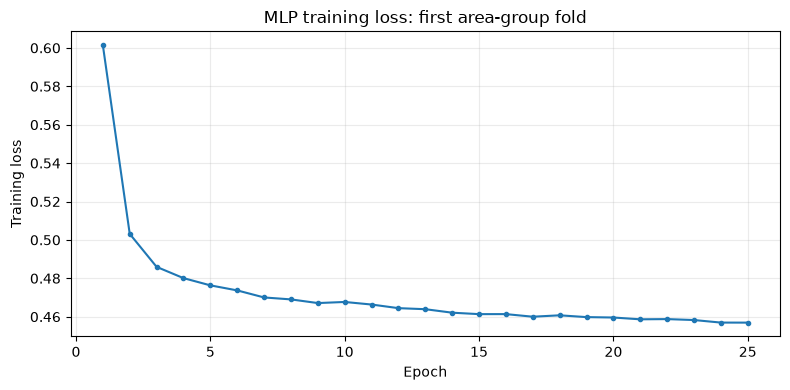

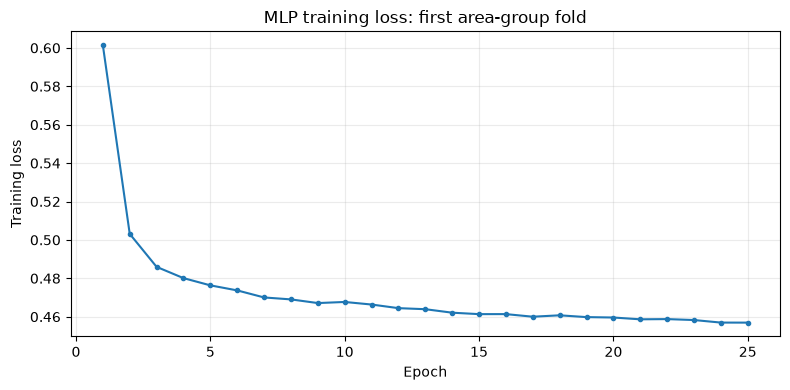

In [6]:
X, y = get_xy(df)
train_indices, validation_indices = area_splits[0]
fold_preprocessor = build_preprocessor()
X_train = fold_preprocessor.fit_transform(X.iloc[train_indices])
first_fold_mlp = MODEL_REGISTRY["mlp"]()
first_fold_mlp.fit(X_train, y.iloc[train_indices])
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(range(1, len(first_fold_mlp.loss_) + 1), first_fold_mlp.loss_, marker="o", markersize=3)
ax.set(xlabel="Epoch", ylabel="Training loss", title="MLP training loss: first area-group fold")
ax.grid(alpha=0.25)
fig.tight_layout()
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
loss_plot_path = FIGURES_DIR / "mlp_training_loss.png"
fig.savefig(loss_plot_path, dpi=150, bbox_inches="tight")
print(f"Saved loss plot to {loss_plot_path}; recorded {len(first_fold_mlp.loss_)} epochs.")
display(fig)

**My observations:** The first area fold recorded training loss for all 25 fixed epochs. This plot shows training loss only; it is not evidence by itself that the model generalizes to other folds or storms.